In [48]:
import numpy as np
import matplotlib .pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers


In [3]:
sentences = [
    "the cat eats fish",
    "the dog eats meat",
    "the bird eats seeds",
    "the cow eats grass",
    "the cat drinks milk",
    "the dog drinks water",
    "the bird sings song",
    "the cow gives milk"
]
print("Sentences :",len(sentences))

Sentences : 8


In [5]:
words = " ".join(sentences).split()
vocab = sorted(set(words))
word_to_id = {
    word : i for i,word in enumerate(vocab)
}
id_to_word = {
    i : word for word ,i in word_to_id.items()
}
print ("Vocabulary :",vocab)
print ("Vocabulary Size :", len(vocab))

Vocabulary : ['bird', 'cat', 'cow', 'dog', 'drinks', 'eats', 'fish', 'gives', 'grass', 'meat', 'milk', 'seeds', 'sings', 'song', 'the', 'water']
Vocabulary Size : 16


In [50]:
X = []
Y = []
for sentence in sentences :
    token = sentence.split()
    for i in range (1,len(token)-1):
        context = [
            word_to_id[token[i-1]],
            word_to_id[token[i+1]]
        ]
        target = word_to_id[token[i]]

        X.append(context)
        Y.append(target)
        
X = np.array(X)
Y = np.array(Y)
print("Context shape:", X.shape)
print("Target shape:", Y.shape)
       
      

Context shape: (16, 2)
Target shape: (16,)


In [51]:
model = keras.Sequential([
    keras.Input(shape=(2,)),

    layers.Embedding(
        input_dim = len(vocab),
        output_dim = 8
    ),

    layers.GlobalAveragePooling1D(),
    layers.Dense(
        len(vocab),
        activation = "softmax"
    )

])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 2, 8)           │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_2      │ (None, 8)              │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           144 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 272 (1.06 KB)

 Trainable params: 272 (1.06 KB)

 Non-trainable params: 0 (0.00 B)

In [52]:
model.compile (
optimizer=keras.optimizers.Adam(learning_rate = 0.01),
loss = "sparse_categorical_crossentropy",
metrics = ["accuracy"]
)


In [53]:
history = model.fit (
    X,
    Y,
    epochs = 200,
    verbose = 0
)

In [54]:
context_words = ["bird","seeds"]
context_ids = np.array ([[
    word_to_id["bird"],
    word_to_id["seeds"]
]])
prediction = model.predict(context_ids,verbose =0)
predicted_id = np.argmax(prediction[0])
predicted_word = id_to_word[predicted_id]

print("Context Words :",context_words)
print("Predicted Word :",predicted_word)

Context Words : ['bird', 'seeds']
Predicted Word : eats


In [55]:
loss, accuracy = model.evaluate(X,Y,verbose = 0)
print("Loss : ",round(loss,4))
print("Accuracy :",round (accuracy * 100 ,2), "%")

Loss :  0.4443
Accuracy : 75.0 %


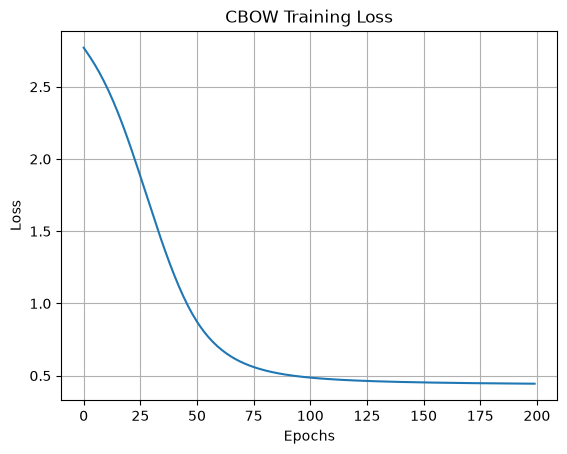

In [56]:
plt.plot(history.history["loss"])
plt.title("CBOW Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid(True)
plt.show()